空间维度分析
分析对象：候客站台（类比基站）与城市空间结构
    1 站台表初识：62 个 ORIGIN_STAND，每站台发车趟次（类比扇区数）
    2 行程能否关联上站台（类比信令关联基站表）
    3 站台定位：无工参坐标，用各站台发车首点中位数反推坐标
    4 点落面：1km 网格划分都市区，首点落入网格（类比点落区县）
    5 维度表 dim_stand
    6 站台间距：KDTree 求最近邻（类比站点间距）

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import taxi_common as tc
from matplotlib.ticker import FuncFormatter
from scipy.spatial import cKDTree

import taxi_common as tc

SCRIPT = "空间维度分析"
tc.AUTHOR = "高帅龙 2428324009"
SOURCE = tc.source_line(SCRIPT)
tc.apply_theme()

dwd = pd.read_pickle(tc.CACHE_DIR / "dwd.pkl")

In [8]:
# 站台表初识
print("站台表初识\n")
has_stand = dwd[dwd["ORIGIN_STAND"].notna()].copy()
stand_trips = has_stand["ORIGIN_STAND"].astype(int).value_counts()
print(f"站台总数 {len(stand_trips)}；有站台记录的趟次 {len(has_stand):,}")
print("发车趟次 top10：\n", stand_trips.head(10).to_string())
print(f"\n每站台发车趟次：中位 {stand_trips.median():.0f}，"
      f"最多 {stand_trips.max()}（{stand_trips.idxmax()} 号），最少 {stand_trips.min()}")

站台表初识

站台总数 62；有站台记录的趟次 49,203
发车趟次 top10：
 ORIGIN_STAND
15    4958
57    3225
9     2265
23    2207
18    2022
36    1798
13    1619
33    1614
12    1492
53    1476

每站台发车趟次：中位 524，最多 4958（15 号），最少 2


In [9]:
# 行程关联站台
print("行程关联站台\n")
# 类比信令关联基站：按 CALL_TYPE 统计站台关联情况
by_type = dwd.groupby("CALL_TYPE").agg(
    趟次数=("TRIP_ID", "size"),
    关联站台=("ORIGIN_STAND", "count")
)

by_type["关联率"] = by_type["关联站台"] / by_type["趟次数"]

print(by_type.to_string())

# 统计全量及 B/C 型行程的站台关联率
overall = dwd["ORIGIN_STAND"].notna().mean()

bc = dwd[dwd["CALL_TYPE"].isin(["B", "C"])]
bc_rate = bc["ORIGIN_STAND"].notna().mean() if len(bc) > 0 else np.nan

print(f"\n全量站台关联率：{overall:.1%}（包含 A 型行程）")
print(f"B/C 型站台关联率：{bc_rate:.1%}（不包含 A 型行程）")

行程关联站台

             趟次数   关联站台       关联率
CALL_TYPE                        
A          20932      0  0.000000
B          49813  49203  0.987754
C          28873      0  0.000000

全量站台关联率：49.4%（包含 A 型行程）
B/C 型站台关联率：62.5%（不包含 A 型行程）


In [10]:
# 站台定位（反推坐标）
print("站台定位（用首点中位数反推）\n")
stand_xy = (has_stand.assign(STAND=has_stand["ORIGIN_STAND"].astype(int))
            .groupby("STAND").agg(
                lng=("lng0", "median"), lat=("lat0", "median"),
                发车趟次=("TRIP_ID", "size"),
                首点离散度=("lng0", lambda s: np.std(s) * 111000 * .75)))
print(f"定位站台 {len(stand_xy)} 个；离散度中位 {stand_xy['首点离散度'].median():.0f} m"
      "（越小说明首点越集中、定位越可信）")
print(stand_xy.sort_values("发车趟次", ascending=False).head(8).to_string())

站台定位（用首点中位数反推）

定位站台 62 个；离散度中位 107 m（越小说明首点越集中、定位越可信）
            lng        lat  发车趟次       首点离散度
STAND                                       
15    -8.585667  41.148558  4958   76.850759
57    -8.610849  41.145651  3225  114.764649
9     -8.606475  41.144625  2265  168.583466
23    -8.612568  41.145984  2207  108.477453
18    -8.619840  41.148009  2022  187.678215
36    -8.649432  41.154309  1798   89.730635
13    -8.628264  41.157414  1619  164.387143
33    -8.600112  41.182704  1614  218.757441


In [11]:
# 点落面：1km 网格
print("点落面：1km 网格\n")
LAT0 = 41.15
KM_LAT = 1 / 111.0
KM_LNG = 1 / (111.32 * np.cos(np.radians(LAT0)))
lng_min, lat_min = dwd["lng0"].min(), dwd["lat0"].min()
dwd = dwd.copy()
dwd["gx"] = np.floor((dwd["lng0"] - lng_min) / KM_LNG).astype(int)
dwd["gy"] = np.floor((dwd["lat0"] - lat_min) / KM_LAT).astype(int)
grid = dwd.groupby(["gx", "gy"]).agg(
    趟次=("TRIP_ID", "size"),
    车辆=("TAXI_ID", "nunique"),
    lng=("lng0", "median"), lat=("lat0", "median")).reset_index()
print(f"覆盖网格 {len(grid)} 个；top 网格：")
print(grid.sort_values("趟次", ascending=False).head(8).to_string(index=False))

# 写维度表
dim_stand = stand_xy.reset_index()
dim_stand.to_pickle(tc.CACHE_DIR / "dim_stand.pkl")
dwd.to_pickle(tc.CACHE_DIR / "dwd.pkl")
print("\n维度表 dim_stand / 网格 dwd 已更新")

点落面：1km 网格

覆盖网格 298 个；top 网格：
 gx  gy    趟次  车辆       lng       lat
 14  24 20663 422 -8.610912 41.146398
 14  23  7118 394 -8.613882 41.140845
 13  25  6244 408 -8.628264 41.157567
 16  24  6052 342 -8.585667 41.148567
 13  24  4850 400 -8.620020 41.148045
 12  25  4360 378 -8.639622 41.159673
 15  24  3488 383 -8.599567 41.149143
 11  25  3476 334 -8.649414 41.154354

维度表 dim_stand / 网格 dwd 已更新


In [12]:
# 站台间距 KDTree
print("站台间距（KDTree）\n")
xy = stand_xy[["lng", "lat"]].to_numpy()
x_m = np.radians(xy[:, 0]) * 111320 * np.cos(np.radians(LAT0))
y_m = np.radians(xy[:, 1]) * 110540
tree = cKDTree(np.column_stack([x_m, y_m]))
d, _ = tree.query(np.column_stack([x_m, y_m]), k=2)
nn = d[:, 1]     # 第 1 列=自己(0)，第 2 列=最近邻
print(f"相邻站台最近距离：中位 {np.median(nn):.0f} m，"
      f"P10 {np.quantile(nn,.1):.0f} m，最大 {nn.max():.0f} m")

站台间距（KDTree）

相邻站台最近距离：中位 7 m，P10 3 m，最大 23 m


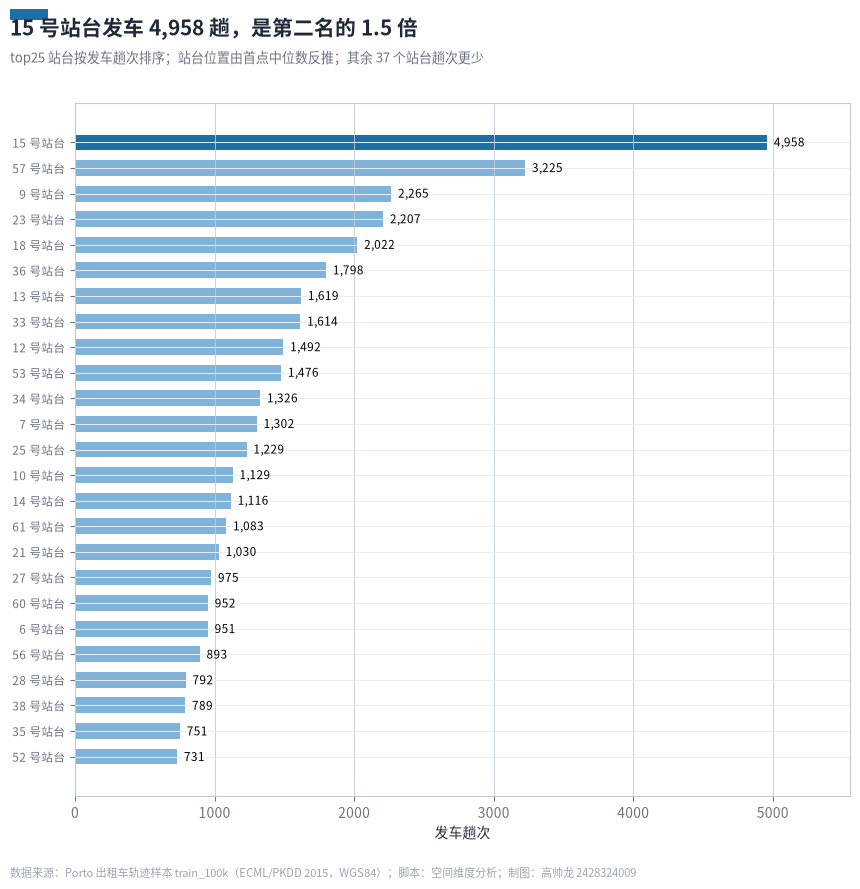

In [13]:
# 站台发车趟次
fig, ax = plt.subplots(figsize=(10, 9), dpi=100)
top = stand_trips.head(25)
colors = [tc.MAIN if i == 0 else tc.MAIN_MID for i in range(len(top))]
ax.barh(range(len(top)), top.values, color=colors, height=0.62)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{i} 号站台" for i in top.index], fontsize=8.5)
ax.invert_yaxis()
for i, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, i, f"{v:,}", va="center", fontsize=8.5)
ax.set_xlim(0, top.max() * 1.12)
ax.set_xlabel("发车趟次")
ax.grid(axis="x", color=tc.GRAY, lw=0.6)
tc.finish(
    fig,
    f"{top.idxmax()} 号站台发车 {top.max():,} 趟，是第二名的 {top.iloc[0]/top.iloc[1]:.1f} 倍",
    "top25 站台按发车趟次排序；站台位置由首点中位数反推；其余 37 个站台趟次更少",
    SOURCE, "D3_01_站台发车趟次.png")
plt.show()

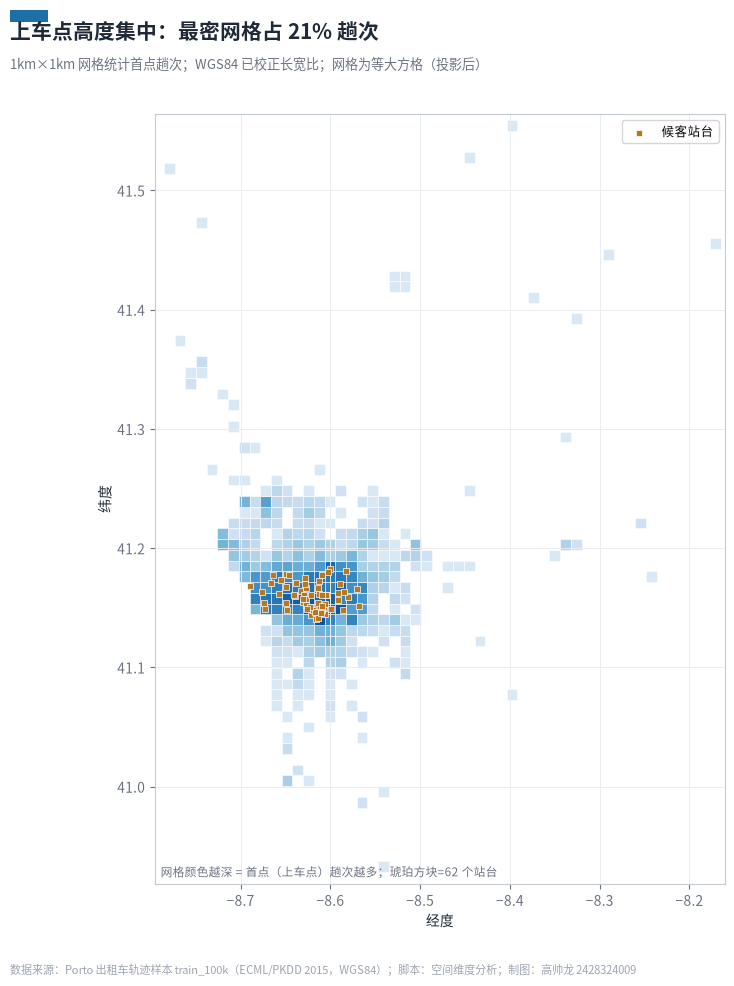

In [14]:
# 网格空间热力
fig, ax = plt.subplots(figsize=(9.5, 10), dpi=100)
# 1km 网格方格，颜色按趟次（对数色阶），跨数量级
gn = grid["趟次"].values
bins = np.geomspace(max(gn.min(), 1), gn.max(), 10)
cmap = plt.cm.Blues

for _, r in grid.iterrows():
    n = r["趟次"]
    c = cmap(
        0.15 + 0.8 * (
            np.log10(max(n, 1)) / np.log10(max(gn.max(), 2))
        )
    )

    # 根据网格编号计算左下角坐标，而不是使用网格内点的中位数
    x_left = lng_min + r["gx"] * KM_LNG
    y_bottom = lat_min + r["gy"] * KM_LAT

    ax.add_patch(plt.Rectangle(
        (x_left, y_bottom),
        KM_LNG,
        KM_LAT,
        facecolor=c,
        edgecolor="white",
        lw=0.4
    ))
# 叠加站台点
ax.scatter(stand_xy["lng"], stand_xy["lat"], marker="s", s=18,
           facecolor=tc.AMBER, edgecolor="white", lw=0.5, zorder=5,
           label="候客站台")
ax.set_aspect(1 / np.cos(np.radians(LAT0)))     # 长宽比校正（规范第 5 节）
ax.set_xlim(dwd["lng0"].min() - .01, dwd["lng0"].max() + .01)
ax.set_ylim(dwd["lat0"].min() - .01, dwd["lat0"].max() + .01)
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
ax.legend(loc="upper right", fontsize=9)
# 色阶说明
ax.text(0.01, 0.01, "网格颜色越深 = 首点（上车点）趟次越多；琥珀方块=62 个站台",
        transform=ax.transAxes, fontsize=8.5, color=tc.MUTED)
tc.finish(
    fig,
    f"上车点高度集中：最密网格占 {grid.sort_values('趟次',ascending=False).iloc[0]['趟次']/grid['趟次'].sum():.0%} 趟次",
    "1km×1km 网格统计首点趟次；WGS84 已校正长宽比；网格为等大方格（投影后）",
    SOURCE, "D3_02_上车点网格热力.png")
plt.show()

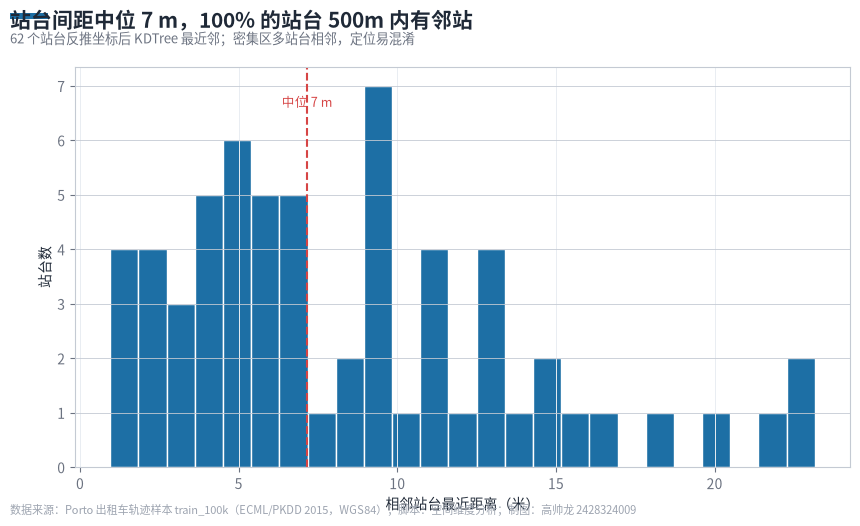

完成：图片已保存至 E:\HuaweiMoveData\Users\l1513\Documents\xwechat_files\wxid_jpkvn0ecjex822_5880\msg\file\2026-10\taxi_analysis(1)\taxi_analysis\image


In [15]:
# 站台间距
fig, ax = plt.subplots(figsize=(10, 5.2), dpi=100)
ax.hist(nn, bins=25, color=tc.MAIN, edgecolor="white")
ax.axvline(np.median(nn), color=tc.RED, lw=1.5, ls="--")
ax.text(np.median(nn), ax.get_ylim()[1] * .9, f"中位 {np.median(nn):.0f} m",
        color=tc.RED, fontsize=9, ha="center")
ax.set_xlabel("相邻站台最近距离（米）")
ax.set_ylabel("站台数")
ax.grid(axis="y", color=tc.GRAY, lw=0.6)
tc.finish(
    fig,
    f"站台间距中位 {np.median(nn):.0f} m，{np.mean(nn<500):.0%} 的站台 500m 内有邻站",
    "62 个站台反推坐标后 KDTree 最近邻；密集区多站台相邻，定位易混淆",
    SOURCE, "D3_03_站台间距.png")
plt.show()
print("完成：图片已保存至", tc.IMAGE_DIR)